# `test_pipeline_binaire_optionB_morphologie.ipynb`

## Option B — Test binaire morphologique : défauts linéaires vs défauts de relief

**Projet :** MALLOULINOVA — Qualification fiable des pièces repeintes vs peinture d'origine par vision artificielle smartphone  
**Référence :** MALL-STG-ETE-2026-PAINT-01  
**Semaine :** S4 — Développement du pipeline logiciel  
**Rôle du notebook :** valider le pipeline binaire complet sur une tâche proxy plus difficile que `SCRATCH` vs `ORANGEPEEL`.

### Objectif technique

Ce notebook teste la séparation morphologique suivante :

```text
Classe 0 : défauts linéaires
Classe 1 : défauts de relief / texture
```

Chaîne validée :

```text
Roboflow Paint Defects ZIP
        │
        ▼
Extraction + lecture des fichiers _classes.csv
        │
        ▼
Réorganisation en 2 classes morphologiques : Lineaire / Relief
        │
        ▼
Chargement Keras image_dataset_from_directory
        │
        ▼
Redimensionnement 384×384 + tf.data.AUTOTUNE
        │
        ▼
Data augmentation
        │
        ▼
Phase 1 : EfficientNet-B0 backbone gelé
        │
        ▼
Phase 2 : fine-tuning des dernières couches
        │
        ▼
Évaluation : Accuracy, Precision, Recall, F1, AUC, matrice de confusion
        │
        ▼
Inférence image individuelle + seuil de rejet → Incertain
        │
        ▼
Sauvegarde modèle + métriques + rapport technique
```

> ⚠️ **Important :** cette tâche reste un proxy technique. Elle ne remplace pas la validation finale `Lineaire / Relief` sur le dataset propriétaire macroscopique Setup F.


## 1. Mapping Option B — morphologie linéaire vs relief

Le dataset Roboflow Paint Defects contient 7 classes :

```text
BLISTERING, BUBBLES, FISHEYE, ORANGEPEEL, SAG, SCRATCH, SOLVENTPOP
```

Pour rendre le test binaire plus intéressant scientifiquement, on regroupe les défauts selon leur morphologie visuelle :

| Classe pipeline | Classes Roboflow regroupées | Justification morphologique |
|---|---|---|
| `Lineaire` | `SCRATCH`, `SAG` | rayures, coulures ou défauts directionnels/allongés |
| `Relief` | `BLISTERING`, `BUBBLES`, `FISHEYE`, `ORANGEPEEL`, `SOLVENTPOP` | défauts de relief, bulles, cratères, peau d'orange, micro-textures |

Ce mapping teste mieux la capacité d'EfficientNet-B0 à séparer :

```text
formes directionnelles / linéaires
vs
textures de surface / reliefs locaux
```

Ce test est plus riche que le mapping simple `SCRATCH` vs `ORANGEPEEL`, car il utilise les 7 classes Roboflow et force le modèle à apprendre une séparation morphologique plus générale.


In [ ]:
# ============================================================
# 3. Imports, environnement et reproductibilité
# ============================================================

!pip install -q scikit-learn pandas matplotlib

import os
import json
import random
import shutil
import zipfile
import datetime
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
)

try:
    import google.colab  # type: ignore
    IN_COLAB = True
except Exception:
    IN_COLAB = False

print("TensorFlow version:", tf.__version__)
print("Exécution dans Colab:", IN_COLAB)
print("GPU disponibles:", tf.config.list_physical_devices("GPU"))

# Reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Évite une allocation totale immédiate de la mémoire GPU
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as exc:
        print("Memory growth non modifié:", exc)


TensorFlow version: 2.20.0
Exécution dans Colab: True
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# ============================================================
# 4. Configuration globale
# ============================================================

PROJECT_NAME = "MALLOULINOVA_test_pipeline_binaire_roboflow"

# Chemin du ZIP Roboflow dans Colab.
# Après upload dans Colab, le fichier doit être ici : /content/roboflow_paint_defects.zip
BASE_DIR = Path("/content") if IN_COLAB else Path(".")
ZIP_PATH = BASE_DIR / "roboflow_paint_defects.zip"
EXTRACT_DIR = BASE_DIR / "roboflow_paint_defects"

# Dataset binaire généré par ce notebook
BINARY_DATA_DIR = BASE_DIR / "roboflow_paint_defects_binary_morphologie_lineaire_vs_relief"

# Sorties techniques
OUTPUT_DIR = BASE_DIR / "outputs_test_pipeline_binaire"

# Format retenu dans le projet MALLOULINOVA / Setup F
IMG_SIZE = (384, 384)
BATCH_SIZE = 16  # 16 recommandé sur T4 à 384×384 ; mettre 32 si mémoire suffisante

# Classes finales du pipeline binaire
CLASS_NAMES_TARGET = ["Lineaire", "Relief"]
NUM_CLASSES = len(CLASS_NAMES_TARGET)

# Mapping Roboflow → classes binaires du pipeline.
# Mapping proxy technique, pas vérité métier.
BINARY_MAPPING = {
    "Lineaire": ["SCRATCH", "SAG"],
    "Relief": ["BLISTERING", "BUBBLES", "FISHEYE", "ORANGEPEEL", "SOLVENTPOP"],
}

# Entraînement rapide pour validation technique.
# Pour un test plus complet : Phase 1 = 15-20 epochs, Phase 2 = 10-15 epochs.
EPOCHS_PHASE1 = 8
EPOCHS_PHASE2 = 5

LR_PHASE1 = 1e-3
LR_PHASE2 = 1e-5
FINE_TUNE_LAST_N = 30

# Seuil initial du projet : si max(softmax) < seuil → Incertain
CONFIDENCE_THRESHOLD = 0.65

# Recréer le dataset binaire à chaque exécution
RESET_BINARY_DATASET = True

# Création des dossiers de sortie
for subdir in ["weights", "metrics", "figures", "predictions"]:
    (OUTPUT_DIR / subdir).mkdir(parents=True, exist_ok=True)

print("ZIP_PATH        :", ZIP_PATH)
print("EXTRACT_DIR     :", EXTRACT_DIR)
print("BINARY_DATA_DIR :", BINARY_DATA_DIR)
print("OUTPUT_DIR      :", OUTPUT_DIR)
print("IMG_SIZE        :", IMG_SIZE)
print("BATCH_SIZE      :", BATCH_SIZE)
print("Classes cible   :", CLASS_NAMES_TARGET)
print("Mapping binaire :", BINARY_MAPPING)


ZIP_PATH        : /content/roboflow_paint_defects.zip
EXTRACT_DIR     : /content/roboflow_paint_defects
BINARY_DATA_DIR : /content/roboflow_paint_defects_binary_morphologie_lineaire_vs_relief
OUTPUT_DIR      : /content/outputs_test_pipeline_binaire
IMG_SIZE        : (384, 384)
BATCH_SIZE      : 16
Classes cible   : ['Lineaire', 'Relief']
Mapping binaire : {'Lineaire': ['SCRATCH', 'SAG'], 'Relief': ['BLISTERING', 'BUBBLES', 'FISHEYE', 'ORANGEPEEL', 'SOLVENTPOP']}


## 5. Extraction du ZIP Roboflow

Structure attendue après extraction :

```text
/content/roboflow_paint_defects/
├── train/
│   ├── *.jpg
│   └── _classes.csv
├── valid/
│   ├── *.jpg
│   └── _classes.csv
└── test/
    ├── *.jpg
    └── _classes.csv
```


In [4]:
# ============================================================
# 5. Extraction du ZIP Roboflow
# ============================================================

if not EXTRACT_DIR.exists():
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            f"ZIP introuvable : {ZIP_PATH}\n"
            "Dans Colab, uploadez d'abord roboflow_paint_defects.zip dans /content."
        )

    print(f"Extraction de {ZIP_PATH} ...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(BASE_DIR)
else:
    print("Dataset déjà extrait :", EXTRACT_DIR)

# Vérification rapide
for split in ["train", "valid", "test"]:
    split_dir = EXTRACT_DIR / split
    csv_path = split_dir / "_classes.csv"
    n_images = len(list(split_dir.glob("*.jpg"))) if split_dir.exists() else 0
    print(f"{split:<5} | images={n_images:<5} | csv_exists={csv_path.exists()}")


Extraction de /content/roboflow_paint_defects.zip ...
train | images=1424  | csv_exists=True
valid | images=168   | csv_exists=True
test  | images=83    | csv_exists=True


## 6. Lecture dynamique des classes Roboflow

Roboflow encode les labels dans `_classes.csv`. Les colonnes après `filename` correspondent aux classes.


In [5]:
# ============================================================
# 6. Détection dynamique des classes Roboflow
# ============================================================

sample_csv_path = EXTRACT_DIR / "train" / "_classes.csv"
if not sample_csv_path.exists():
    sample_csv_path = EXTRACT_DIR / "test" / "_classes.csv"

if not sample_csv_path.exists():
    raise FileNotFoundError("Aucun _classes.csv trouvé dans train/test.")

df_sample = pd.read_csv(sample_csv_path)
df_sample.columns = [col.strip() for col in df_sample.columns]

CATEGORY_NAMES = [col for col in df_sample.columns if col.lower() != "filename"]
print("📋 Catégories Roboflow détectées :", CATEGORY_NAMES)

# Vérifier que les classes du mapping existent
missing = []
for target, source_classes in BINARY_MAPPING.items():
    for src_cls in source_classes:
        if src_cls not in CATEGORY_NAMES:
            missing.append(src_cls)

if missing:
    raise ValueError(f"Classes absentes du dataset Roboflow : {missing}")
else:
    print("✅ Mapping compatible avec les classes détectées.")

print("Aperçu CSV :")
display(df_sample.head())


📋 Catégories Roboflow détectées : ['BLISTERING', 'BUBBLES', 'FISHEYE', 'ORANGEPEEL', 'SAG', 'SCRATCH', 'SOLVENTPOP']
✅ Mapping compatible avec les classes détectées.
Aperçu CSV :


,filename,BLISTERING,BUBBLES,FISHEYE,ORANGEPEEL,SAG,SCRATCH,SOLVENTPOP
0,DSC_0132_JPG_jpg.rf.6296b5c0a40230659fff5e0153...,0,0,0,0,1,0,0
1,rotated_104_jpg.rf.f6368d97f4d803b86297ed721b7...,1,0,0,0,0,0,0
2,solvent_pop_b0_87_5ea97df5-63ac-4e88-8b88-7273...,0,0,0,0,0,0,1
3,blur_134_jpg.rf.49d1c5a1345d83a63fafd285220cd4...,0,0,0,1,0,0,0
4,blur_12_jpg.rf.d50c50f0949316a5db556c9d1136f4b...,0,0,0,0,0,1,0


## 7. Réorganisation du dataset Roboflow en 2 classes

La fonction ci-dessous :

1. parcourt `train`, `valid`, `test` ;
2. lit `_classes.csv` ;
3. détecte les labels actifs de chaque image ;
4. copie l'image vers `Origine/` ou `Repeint/` selon `BINARY_MAPPING` ;
5. ignore les classes non utilisées dans le mapping ;
6. ignore les cas ambigus si une image correspond simultanément aux deux groupes.

La sortie est compatible avec `image_dataset_from_directory` :

```text
roboflow_paint_defects_binary_morphologie_lineaire_vs_relief/
├── train/
│   ├── Origine/
│   └── Repeint/
├── val/
│   ├── Origine/
│   └── Repeint/
└── test/
    ├── Origine/
    └── Repeint/
```


In [6]:
# ============================================================
# 7. Réorganisation binaire Roboflow → Lineaire / Relief
# ============================================================

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def reset_dir(path: Path):
    if path.exists():
        shutil.rmtree(path)
    path.mkdir(parents=True, exist_ok=True)


def is_active_label(value):
    """Robuste aux valeurs 1, 1.0, '1', ' 1'."""
    try:
        return int(value) == 1
    except Exception:
        return str(value).strip() == "1"


def active_labels_from_row(row, categories):
    active = []
    for cls in categories:
        if cls in row and is_active_label(row[cls]):
            active.append(cls)
    return active


def safe_copy(src_path: Path, dst_dir: Path):
    """Copie en évitant les collisions de noms."""
    dst_dir.mkdir(parents=True, exist_ok=True)
    dst_path = dst_dir / src_path.name
    if not dst_path.exists():
        shutil.copy2(src_path, dst_path)
        return dst_path

    stem, suffix = src_path.stem, src_path.suffix
    k = 1
    while True:
        candidate = dst_dir / f"{stem}__dup{k}{suffix}"
        if not candidate.exists():
            shutil.copy2(src_path, candidate)
            return candidate
        k += 1


def build_binary_dataset_from_roboflow(
    extract_dir: Path,
    output_dir: Path,
    binary_mapping: dict,
    category_names: list,
    reset: bool = True,
):
    if reset:
        reset_dir(output_dir)
    else:
        output_dir.mkdir(parents=True, exist_ok=True)

    # Mapping inverse : classe source Roboflow → classe cible binaire
    source_to_target = {}
    for target_class, source_classes in binary_mapping.items():
        for source_class in source_classes:
            source_to_target[source_class] = target_class

    split_map = {"train": "train", "valid": "val", "test": "test"}
    all_rows = []

    for source_split, output_split in split_map.items():
        split_dir = extract_dir / source_split
        csv_path = split_dir / "_classes.csv"

        if not csv_path.exists():
            print(f"⚠️ CSV absent pour {source_split}, split ignoré.")
            continue

        # Créer les dossiers cibles même si aucun fichier n'est copié
        for target_class in binary_mapping.keys():
            (output_dir / output_split / target_class).mkdir(parents=True, exist_ok=True)

        df = pd.read_csv(csv_path)
        df.columns = [col.strip() for col in df.columns]

        counts = Counter()
        skipped_unmapped = 0
        skipped_ambiguous = 0
        skipped_missing = 0

        for _, row in df.iterrows():
            filename = str(row["filename"]).strip()
            src_path = split_dir / filename

            if not src_path.exists():
                skipped_missing += 1
                continue

            active = active_labels_from_row(row, category_names)
            active_targets = sorted({source_to_target[cls] for cls in active if cls in source_to_target})

            if len(active_targets) == 0:
                skipped_unmapped += 1
                continue

            if len(active_targets) > 1:
                skipped_ambiguous += 1
                continue

            target_class = active_targets[0]
            copied_path = safe_copy(src_path, output_dir / output_split / target_class)
            counts[target_class] += 1

            all_rows.append({
                "source_split": source_split,
                "output_split": output_split,
                "filename": filename,
                "source_path": str(src_path),
                "output_path": str(copied_path),
                "active_labels": ";".join(active),
                "binary_label": target_class,
            })

        print(f"\n[{output_split.upper()}] Distribution binaire :")
        for cls in binary_mapping.keys():
            print(f"  {cls:<10}: {counts[cls]}")
        print(f"  {'TOTAL':<10}: {sum(counts.values())}")
        print(f"  ignorées non mappées : {skipped_unmapped}")
        print(f"  ignorées ambiguës    : {skipped_ambiguous}")
        print(f"  fichiers manquants   : {skipped_missing}")

    manifest_df = pd.DataFrame(all_rows)
    return manifest_df


manifest_df = build_binary_dataset_from_roboflow(
    extract_dir=EXTRACT_DIR,
    output_dir=BINARY_DATA_DIR,
    binary_mapping=BINARY_MAPPING,
    category_names=CATEGORY_NAMES,
    reset=RESET_BINARY_DATASET,
)

manifest_path = OUTPUT_DIR / "metrics" / "binary_dataset_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)
print("\nManifest sauvegardé :", manifest_path)
display(manifest_df.head())



[TRAIN] Distribution binaire :
  Lineaire  : 639
  Relief    : 783
  TOTAL     : 1422
  ignorées non mappées : 2
  ignorées ambiguës    : 0
  fichiers manquants   : 0

[VAL] Distribution binaire :
  Lineaire  : 58
  Relief    : 110
  TOTAL     : 168
  ignorées non mappées : 0
  ignorées ambiguës    : 0
  fichiers manquants   : 0

[TEST] Distribution binaire :
  Lineaire  : 46
  Relief    : 37
  TOTAL     : 83
  ignorées non mappées : 0
  ignorées ambiguës    : 0
  fichiers manquants   : 0

Manifest sauvegardé : /content/outputs_test_pipeline_binaire/metrics/binary_dataset_manifest.csv


,source_split,output_split,filename,source_path,output_path,active_labels,binary_label
0,train,train,DSC_0132_JPG_jpg.rf.6296b5c0a40230659fff5e0153...,/content/roboflow_paint_defects/train/DSC_0132...,/content/roboflow_paint_defects_binary_morphol...,SAG,Lineaire
1,train,train,rotated_104_jpg.rf.f6368d97f4d803b86297ed721b7...,/content/roboflow_paint_defects/train/rotated_...,/content/roboflow_paint_defects_binary_morphol...,BLISTERING,Relief
2,train,train,solvent_pop_b0_87_5ea97df5-63ac-4e88-8b88-7273...,/content/roboflow_paint_defects/train/solvent_...,/content/roboflow_paint_defects_binary_morphol...,SOLVENTPOP,Relief
3,train,train,blur_134_jpg.rf.49d1c5a1345d83a63fafd285220cd4...,/content/roboflow_paint_defects/train/blur_134...,/content/roboflow_paint_defects_binary_morphol...,ORANGEPEEL,Relief
4,train,train,blur_12_jpg.rf.d50c50f0949316a5db556c9d1136f4b...,/content/roboflow_paint_defects/train/blur_12_...,/content/roboflow_paint_defects_binary_morphol...,SCRATCH,Lineaire


In [7]:
# ============================================================
# 7.1 Vérification distribution finale
# ============================================================

distribution_rows = []
for subset in ["train", "val", "test"]:
    for class_name in CLASS_NAMES_TARGET:
        folder = BINARY_DATA_DIR / subset / class_name
        n = len([p for p in folder.rglob("*") if p.suffix.lower() in IMAGE_EXTENSIONS]) if folder.exists() else 0
        distribution_rows.append({"subset": subset, "class": class_name, "count": n})

distribution_df = pd.DataFrame(distribution_rows)
distribution_pivot = distribution_df.pivot(index="class", columns="subset", values="count").fillna(0).astype(int)
display(distribution_pivot)

distribution_path = OUTPUT_DIR / "metrics" / "dataset_distribution_binary.csv"
distribution_df.to_csv(distribution_path, index=False)
print("Distribution sauvegardée :", distribution_path)

# Vérification stricte : 2 classes non vides dans chaque split
for subset in ["train", "val", "test"]:
    for class_name in CLASS_NAMES_TARGET:
        n = int(distribution_df[(distribution_df["subset"] == subset) & (distribution_df["class"] == class_name)]["count"].iloc[0])
        if n == 0:
            raise ValueError(f"Split {subset}, classe {class_name} vide. Vérifiez BINARY_MAPPING.")

print("✅ Dataset binaire prêt pour Keras.")


subset,test,train,val
class,,,
Lineaire,46,639,58
Relief,37,783,110


Distribution sauvegardée : /content/outputs_test_pipeline_binaire/metrics/dataset_distribution_binary.csv
✅ Dataset binaire prêt pour Keras.


## 8. Chargement Keras avec `image_dataset_from_directory`

Choix techniques conformes au pipeline cible :

- `image_size=(384, 384)` ;
- `label_mode='categorical'` pour sortie Softmax 2 classes ;
- `tf.data.AUTOTUNE` ;
- `shuffle=False` pour validation/test afin de garder l'ordre des prédictions.


In [8]:
# ============================================================
# 8. Chargement du dataset binaire avec Keras
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    BINARY_DATA_DIR / "train",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    BINARY_DATA_DIR / "val",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    BINARY_DATA_DIR / "test",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_ds_raw.class_names
assert class_names == CLASS_NAMES_TARGET, f"Ordre de classes inattendu : {class_names}"

# Chemins des images pour export détaillé des prédictions
train_file_paths = list(train_ds_raw.file_paths)
val_file_paths = list(val_ds_raw.file_paths)
test_file_paths = list(test_ds_raw.file_paths)

# Préfetch pour accélérer l'entraînement
train_ds = train_ds_raw.prefetch(AUTOTUNE)
val_ds = val_ds_raw.prefetch(AUTOTUNE)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

print("Classes Keras :", class_names)
print("Batches train :", tf.data.experimental.cardinality(train_ds).numpy())
print("Batches val   :", tf.data.experimental.cardinality(val_ds).numpy())
print("Batches test  :", tf.data.experimental.cardinality(test_ds).numpy())


Found 1422 files belonging to 2 classes.
Found 168 files belonging to 2 classes.
Found 83 files belonging to 2 classes.
Classes Keras : ['Lineaire', 'Relief']
Batches train : 89
Batches val   : 11
Batches test  : 6


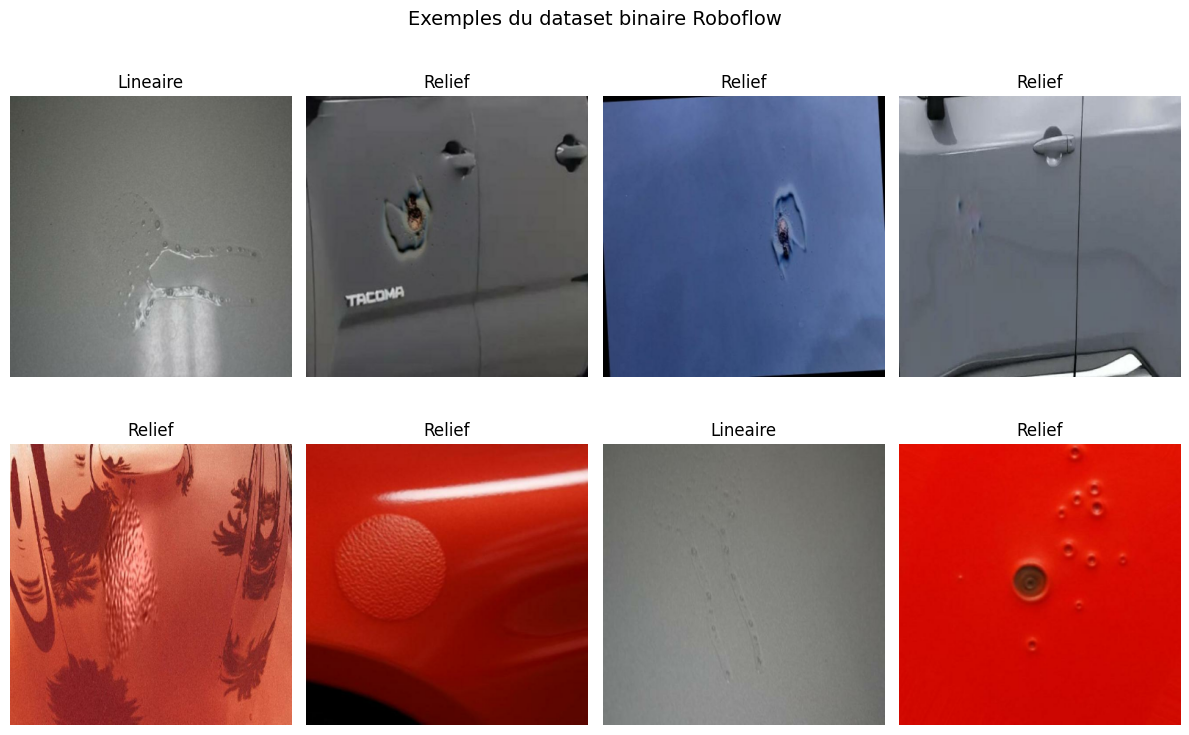

In [9]:
# ============================================================
# 8.1 Visualisation d'un batch
# ============================================================

plt.figure(figsize=(12, 8))
for images, labels in train_ds_raw.take(1):
    n_show = min(8, images.shape[0])
    for i in range(n_show):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = int(np.argmax(labels[i].numpy()))
        plt.title(class_names[label_idx])
        plt.axis("off")
plt.suptitle("Exemples du dataset binaire Roboflow", fontsize=14)
plt.tight_layout()
plt.show()


## 9. Data augmentation

La data augmentation est appliquée uniquement pendant l'entraînement :

- flip horizontal ;
- rotation légère ;
- translation ;
- zoom ;
- contraste ;
- luminosité.

Ces transformations valident le bloc augmentation du futur pipeline. Pour le dataset macroscopique Setup F, elles devront rester modérées afin de ne pas détruire le signal texture.


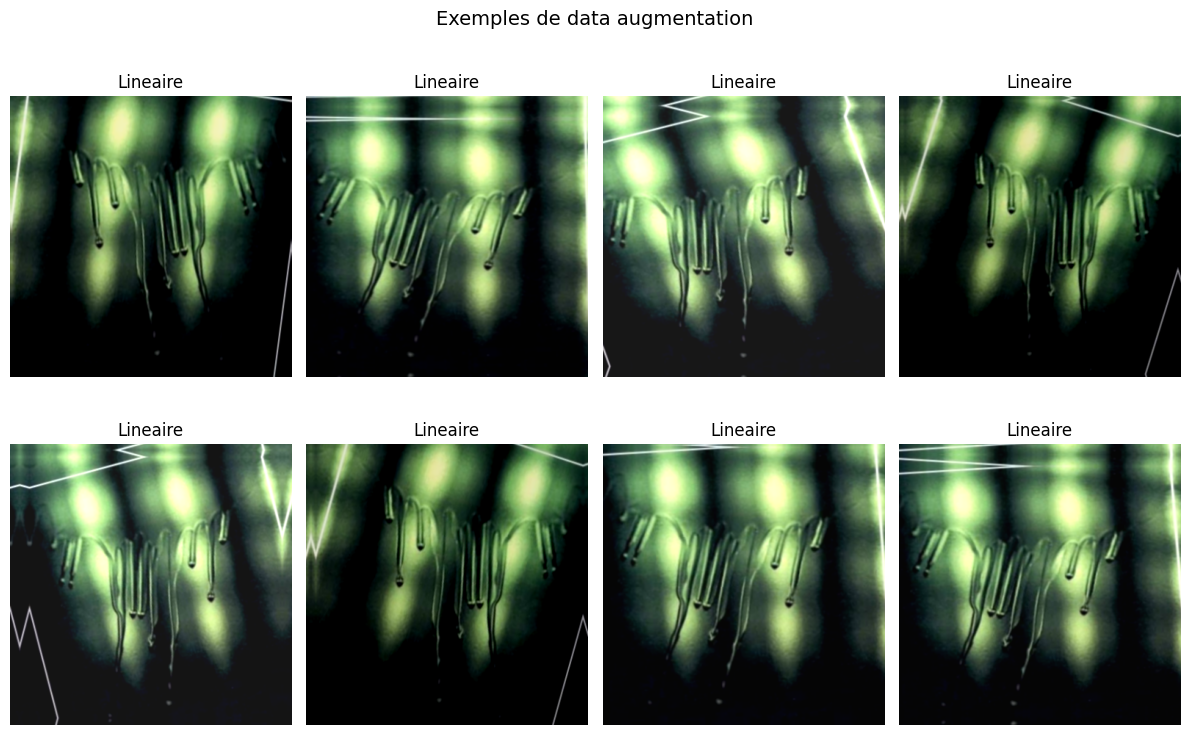

In [10]:
# ============================================================
# 9. Data augmentation Keras
# ============================================================

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.05, seed=SEED),
        layers.RandomTranslation(height_factor=0.05, width_factor=0.05, seed=SEED),
        layers.RandomZoom(height_factor=0.10, width_factor=0.10, seed=SEED),
        layers.RandomContrast(0.15, seed=SEED),
        layers.RandomBrightness(factor=0.10, seed=SEED),
    ],
    name="data_augmentation",
)

# Visualisation rapide
for images, labels in train_ds_raw.take(1):
    sample = images[0:1]
    sample_label = class_names[int(np.argmax(labels[0].numpy()))]
    break

plt.figure(figsize=(12, 8))
for i in range(8):
    augmented = data_augmentation(sample, training=True)
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(tf.cast(tf.clip_by_value(augmented[0], 0, 255), tf.uint8).numpy())
    plt.title(sample_label)
    plt.axis("off")
plt.suptitle("Exemples de data augmentation", fontsize=14)
plt.tight_layout()
plt.show()


## 10. Modèle EfficientNet-B0 binaire — Phase 1 backbone gelé

Architecture :

```text
Entrée 384×384×3
   │
   ├── Data augmentation
   ├── preprocess_input EfficientNet
   ├── EfficientNet-B0 ImageNet sans top, backbone gelé
   ├── GlobalAveragePooling2D
   ├── Dropout 0.4
   ├── Dense 256 ReLU
   ├── Dropout 0.3
   └── Dense 2 Softmax → Lineaire / Relief
```

La Phase 1 entraîne seulement la tête de classification.


In [11]:
# ============================================================
# 10. Construction du modèle EfficientNet-B0 binaire
# ============================================================


def build_efficientnetb0_binary_model(
    img_size=(384, 384),
    num_classes=2,
    dense_units=256,
    dropout_1=0.4,
    dropout_2=0.3,
    l2_reg=1e-4,
):
    inputs = keras.Input(shape=img_size + (3,), name="input_image")

    # Augmentation active uniquement pendant training=True
    x = data_augmentation(inputs)

    # API officielle EfficientNet ; dans certaines versions, cette fonction est un no-op
    # car EfficientNet intègre déjà la normalisation. La conserver garantit la compatibilité.
    x = tf.keras.applications.efficientnet.preprocess_input(x)

    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=img_size + (3,),
    )
    base_model.trainable = False

    # training=False garde les BatchNorm en mode inference, stable pour petit dataset.
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(dropout_1, name="dropout_head_1")(x)
    x = layers.Dense(
        dense_units,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(l2_reg),
        name="dense_texture_head",
    )(x)
    x = layers.Dropout(dropout_2, name="dropout_head_2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="classification_softmax")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="efficientnetb0_binary_roboflow_proxy")
    return model, base_model


model, base_model = build_efficientnetb0_binary_model(
    img_size=IMG_SIZE,
    num_classes=NUM_CLASSES,
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_PHASE1),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()
print("Backbone:", base_model.name)
print("Backbone trainable:", base_model.trainable)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "efficientnetb0_binary_roboflow_proxy"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 12, 12, 1280)   │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head_1 (Dropout)        │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_texture_head (Dense)      │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head_2 (Dropout)        │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_softmax (Dense)  │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,021 (16.70 MB)

 Trainable params: 328,450 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Backbone: efficientnetb0
Backbone trainable: False


In [12]:
# ============================================================
# 10.1 Callbacks Phase 1
# ============================================================

checkpoint_phase1 = OUTPUT_DIR / "weights" / "efficientnet_binaire_phase1_best.keras"

callbacks_phase1 = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_phase1),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

print("Checkpoint Phase 1 :", checkpoint_phase1)


Checkpoint Phase 1 : /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase1_best.keras


In [13]:
# ============================================================
# 10.2 Entraînement Phase 1 : backbone gelé
# ============================================================

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks_phase1,
)


Epoch 1/8
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.8379 - loss: 0.3736
Epoch 1: val_loss improved from None to 0.05899, saving model to /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase1_best.keras

Epoch 1: finished saving model to /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase1_best.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 29s 179ms/step - accuracy: 0.9121 - loss: 0.2534 - val_accuracy: 1.0000 - val_loss: 0.0590 - learning_rate: 0.0010
Epoch 2/8
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.9767 - loss: 0.1072
Epoch 2: val_loss improved from 0.05899 to 0.04742, saving model to /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase1_best.keras

Epoch 2: finished saving model to /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase1_best.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 12s 136ms/step - accuracy: 0.9796 - loss: 0.1016 - val_accuracy: 1.0000 - val_loss: 0.0474 - learning_rate: 0.0010

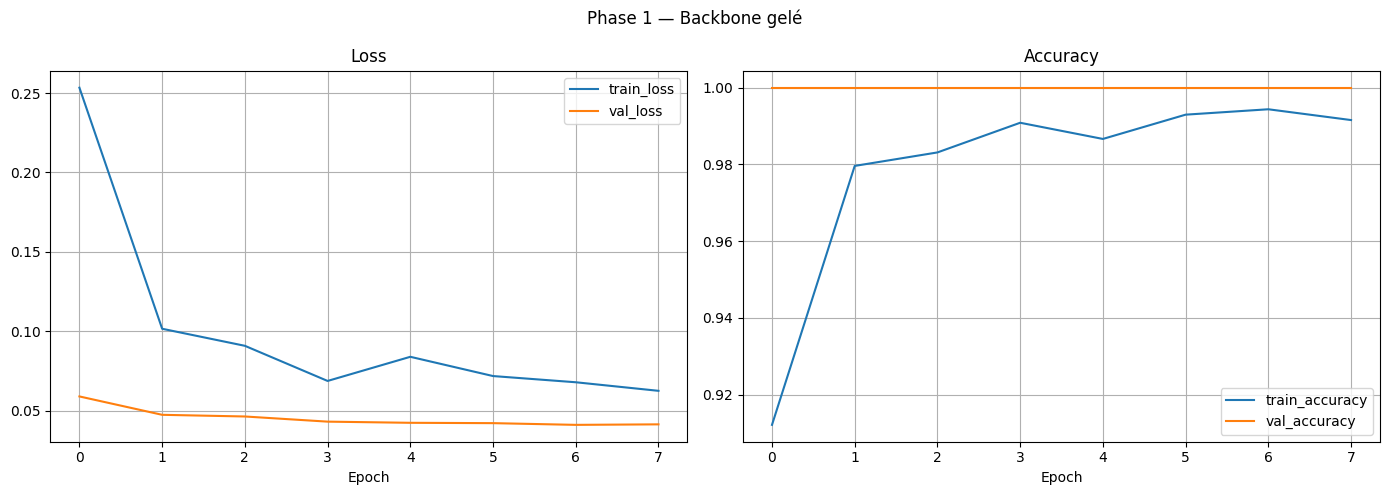

In [14]:
# ============================================================
# 10.3 Courbes Phase 1
# ============================================================


def plot_history(history, title="Historique d'entraînement"):
    hist = history.history
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist.get("loss", []), label="train_loss")
    axes[0].plot(hist.get("val_loss", []), label="val_loss")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(hist.get("accuracy", []), label="train_accuracy")
    axes[1].plot(hist.get("val_accuracy", []), label="val_accuracy")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(history1, "Phase 1 — Backbone gelé")


## 11. Phase 2 — Fine-tuning

Cette phase affine les représentations haut niveau :

- dégel des **30 dernières couches** du backbone ;
- conservation des `BatchNormalization` gelées ;
- learning rate réduit à `1e-5`.


In [15]:
# ============================================================
# 11. Fine-tuning Phase 2
# ============================================================

base_model.trainable = True

# Geler toutes les couches sauf les N dernières
for layer in base_model.layers[:-FINE_TUNE_LAST_N]:
    layer.trainable = False

# Garder toutes les BatchNorm gelées, même dans les couches dégelées
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(1 for layer in base_model.layers if layer.trainable)
n_total = len(base_model.layers)
print(f"Couches trainables du backbone : {n_trainable}/{n_total}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_PHASE2),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

checkpoint_phase2 = OUTPUT_DIR / "weights" / "efficientnet_binaire_phase2_best.keras"

callbacks_phase2 = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_phase2),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
]

initial_epoch = len(history1.history.get("loss", []))
total_epochs = initial_epoch + EPOCHS_PHASE2

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=initial_epoch,
    callbacks=callbacks_phase2,
)


Couches trainables du backbone : 23/238
Epoch 9/13
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.9960 - loss: 0.0571
Epoch 9: val_loss improved from None to 0.04077, saving model to /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase2_best.keras

Epoch 9: finished saving model to /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase2_best.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 29s 188ms/step - accuracy: 0.9965 - loss: 0.0572 - val_accuracy: 1.0000 - val_loss: 0.0408 - learning_rate: 1.0000e-05
Epoch 10/13
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.9944 - loss: 0.0524
Epoch 10: val_loss improved from 0.04077 to 0.04054, saving model to /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase2_best.keras

Epoch 10: finished saving model to /content/outputs_test_pipeline_binaire/weights/efficientnet_binaire_phase2_best.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - accuracy: 0.9965 - loss: 0.0507 - val_accuracy: 

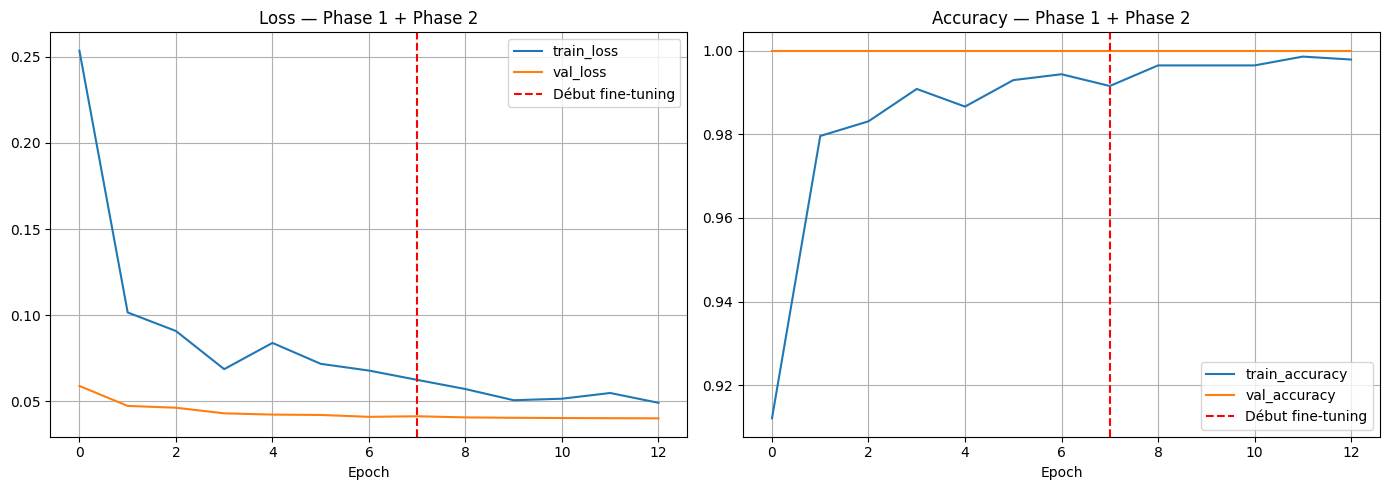

Courbes sauvegardées : /content/outputs_test_pipeline_binaire/figures/training_curves_phase1_phase2.png


In [16]:
# ============================================================
# 11.1 Courbes combinées Phase 1 + Phase 2
# ============================================================


def combine_histories(*histories):
    combined = {}
    for history in histories:
        for key, values in history.history.items():
            combined.setdefault(key, []).extend(values)
    return combined


combined_history = combine_histories(history1, history2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(combined_history.get("loss", []), label="train_loss")
axes[0].plot(combined_history.get("val_loss", []), label="val_loss")
axes[0].axvline(initial_epoch - 1, color="red", linestyle="--", label="Début fine-tuning")
axes[0].set_title("Loss — Phase 1 + Phase 2")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(combined_history.get("accuracy", []), label="train_accuracy")
axes[1].plot(combined_history.get("val_accuracy", []), label="val_accuracy")
axes[1].axvline(initial_epoch - 1, color="red", linestyle="--", label="Début fine-tuning")
axes[1].set_title("Accuracy — Phase 1 + Phase 2")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
history_fig_path = OUTPUT_DIR / "figures" / "training_curves_phase1_phase2.png"
plt.savefig(history_fig_path, dpi=150, bbox_inches="tight")
plt.show()

with open(OUTPUT_DIR / "metrics" / "training_history.json", "w", encoding="utf-8") as f:
    json.dump({k: [float(x) for x in v] for k, v in combined_history.items()}, f, indent=2)

print("Courbes sauvegardées :", history_fig_path)


## 12. Évaluation complète sur le jeu de test

Métriques calculées :

- loss / accuracy Keras ;
- accuracy sklearn ;
- precision / recall / F1 par classe ;
- classification report ;
- matrice de confusion ;
- AUC binaire avec `Relief` comme classe positive ;
- analyse des erreurs.


In [17]:
# ============================================================
# 12. Évaluation Keras sur test
# ============================================================

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 200ms/step - accuracy: 1.0000 - loss: 0.0405
Test loss     : 0.0405
Test accuracy : 1.0000


In [18]:
# ============================================================
# 12.1 Prédictions et métriques sklearn
# ============================================================


def collect_predictions(dataset, model):
    """Collecte y_true, y_prob et y_pred depuis un tf.data.Dataset label_mode='categorical'."""
    y_true_batches = []
    for _, labels in dataset:
        y_true_batches.append(np.argmax(labels.numpy(), axis=1))
    y_true = np.concatenate(y_true_batches, axis=0)
    y_prob = model.predict(dataset, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)
    return y_true, y_prob, y_pred


y_true_test, y_prob_test, y_pred_test = collect_predictions(test_ds, model)

acc = accuracy_score(y_true_test, y_pred_test)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true_test,
    y_pred_test,
    labels=list(range(NUM_CLASSES)),
    average="macro",
    zero_division=0,
)

report_dict = classification_report(
    y_true_test,
    y_pred_test,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df)

# AUC binaire : classe positive = Relief
pos_idx = class_names.index("Relief") if "Relief" in class_names else 1

metrics_summary = {
    "test_loss": float(test_loss),
    "test_accuracy_keras": float(test_accuracy),
    "accuracy_sklearn": float(acc),
    "precision_macro": float(precision_macro),
    "recall_macro": float(recall_macro),
    "f1_macro": float(f1_macro),
    "classes": class_names,
    "positive_class_for_auc": class_names[pos_idx],
    "timestamp": datetime.datetime.now().isoformat(),
    "binary_mapping_proxy": BINARY_MAPPING,
}

try:
    auc_value = roc_auc_score(y_true_test, y_prob_test[:, pos_idx])
    metrics_summary["auc_binary_pos_Relief"] = float(auc_value)
    print(f"AUC binaire classe positive '{class_names[pos_idx]}' : {auc_value:.4f}")
except Exception as exc:
    metrics_summary["auc_binary_pos_Relief"] = None
    print("AUC non calculable :", exc)

print("\nRésumé métriques :")
print(json.dumps(metrics_summary, indent=2, ensure_ascii=False))

metrics_path = OUTPUT_DIR / "metrics" / "metrics_summary_test.json"
report_path = OUTPUT_DIR / "metrics" / "classification_report_test.csv"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2, ensure_ascii=False)
report_df.to_csv(report_path)

print("Métriques sauvegardées :", metrics_path)
print("Classification report sauvegardé :", report_path)


6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 493ms/step


,precision,recall,f1-score,support
Lineaire,1.0,1.0,1.0,46.0
Relief,1.0,1.0,1.0,37.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,83.0
weighted avg,1.0,1.0,1.0,83.0


AUC binaire classe positive 'Relief' : 1.0000

Résumé métriques :
{
  "test_loss": 0.04053022712469101,
  "test_accuracy_keras": 1.0,
  "accuracy_sklearn": 1.0,
  "precision_macro": 1.0,
  "recall_macro": 1.0,
  "f1_macro": 1.0,
  "classes": [
    "Lineaire",
    "Relief"
  ],
  "positive_class_for_auc": "Relief",
  "timestamp": "2026-07-24T12:06:42.519807",
  "binary_mapping_proxy": {
    "Lineaire": [
      "SCRATCH",
      "SAG"
    ],
    "Relief": [
      "BLISTERING",
      "BUBBLES",
      "FISHEYE",
      "ORANGEPEEL",
      "SOLVENTPOP"
    ]
  },
  "auc_binary_pos_Relief": 1.0
}
Métriques sauvegardées : /content/outputs_test_pipeline_binaire/metrics/metrics_summary_test.json
Classification report sauvegardé : /content/outputs_test_pipeline_binaire/metrics/classification_report_test.csv


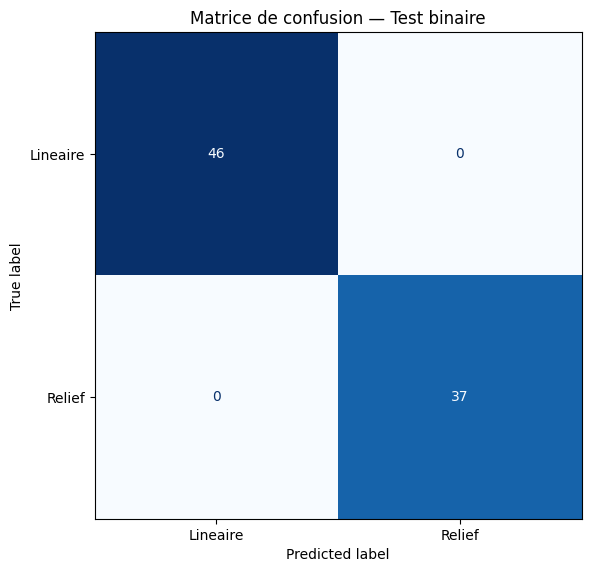

Matrice de confusion sauvegardée : /content/outputs_test_pipeline_binaire/figures/confusion_matrix_test_binary.png


In [19]:
# ============================================================
# 12.2 Matrice de confusion
# ============================================================

cm = confusion_matrix(y_true_test, y_pred_test, labels=list(range(NUM_CLASSES)))

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("Matrice de confusion — Test binaire")
plt.tight_layout()
cm_path = OUTPUT_DIR / "figures" / "confusion_matrix_test_binary.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print("Matrice de confusion sauvegardée :", cm_path)


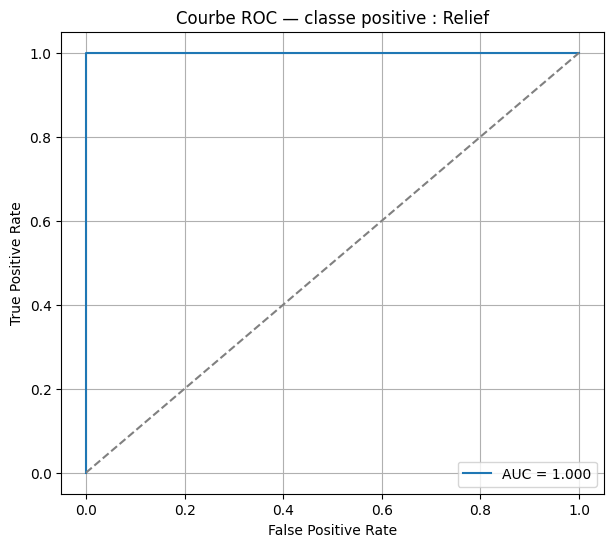

Courbe ROC sauvegardée : /content/outputs_test_pipeline_binaire/figures/roc_curve_test_binary.png


In [20]:
# ============================================================
# 12.3 Courbe ROC binaire
# ============================================================

try:
    fpr, tpr, thresholds_roc = roc_curve(y_true_test, y_prob_test[:, pos_idx], pos_label=pos_idx)
    auc_value = roc_auc_score(y_true_test, y_prob_test[:, pos_idx])

    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"AUC = {auc_value:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"Courbe ROC — classe positive : {class_names[pos_idx]}")
    plt.legend()
    plt.grid(True)
    roc_path = OUTPUT_DIR / "figures" / "roc_curve_test_binary.png"
    plt.savefig(roc_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Courbe ROC sauvegardée :", roc_path)
except Exception as exc:
    print("Courbe ROC non calculable :", exc)


In [21]:
# ============================================================
# 12.4 Analyse des erreurs
# ============================================================

index_to_class = {i: c for i, c in enumerate(class_names)}
y_conf_test = np.max(y_prob_test, axis=1)
errors = np.where(y_true_test != y_pred_test)[0]

total = len(y_true_test)
print(f"\n{'='*60}")
print(f"ANALYSE DES ERREURS ({len(errors)} erreurs sur {total} images)")
print(f"{'='*60}")

error_rows = []
for idx in errors:
    error_rows.append({
        "file_path": test_file_paths[idx],
        "image": os.path.basename(test_file_paths[idx]),
        "true_class": index_to_class[int(y_true_test[idx])],
        "pred_class": index_to_class[int(y_pred_test[idx])],
        "confidence": float(y_conf_test[idx]),
        "confidence_percent": float(y_conf_test[idx] * 100),
    })

error_df = pd.DataFrame(error_rows)
error_path = OUTPUT_DIR / "predictions" / "test_errors.csv"
error_df.to_csv(error_path, index=False)

if len(error_df) > 0:
    display(error_df)
else:
    print("🎉 Aucune erreur sur le jeu de test.")

print("Analyse erreurs sauvegardée :", error_path)



ANALYSE DES ERREURS (0 erreurs sur 83 images)
🎉 Aucune erreur sur le jeu de test.
Analyse erreurs sauvegardée : /content/outputs_test_pipeline_binaire/predictions/test_errors.csv


## 13. Seuil de rejet de confiance → état `Incertain`

Le modèle reste entraîné sur **2 classes uniquement** : `Lineaire` et `Relief`.

L'état `Incertain` est produit en post-traitement :

```text
si max(softmax) >= seuil : verdict = classe prédite
sinon                    : verdict = Incertain
```

Valeur initiale du projet : **0.65**.


In [22]:
# ============================================================
# 13. Grid search simple du seuil de rejet
# ============================================================


def threshold_grid_metrics(y_true, y_prob, class_names, thresholds, pos_idx=1):
    rows = []
    raw_pred = np.argmax(y_prob, axis=1)
    conf = np.max(y_prob, axis=1)

    for thr in thresholds:
        accepted = conf >= thr
        n_total = len(y_true)
        n_accepted = int(np.sum(accepted))
        n_uncertain = n_total - n_accepted

        if n_accepted > 0:
            y_true_acc = y_true[accepted]
            y_pred_acc = raw_pred[accepted]
            acc_acc = accuracy_score(y_true_acc, y_pred_acc)
            precision_pos = precision_score(y_true_acc, y_pred_acc, pos_label=pos_idx, zero_division=0)
            recall_pos = recall_score(y_true_acc, y_pred_acc, pos_label=pos_idx, zero_division=0)
            f1_pos = f1_score(y_true_acc, y_pred_acc, pos_label=pos_idx, zero_division=0)
        else:
            acc_acc = np.nan
            precision_pos = np.nan
            recall_pos = np.nan
            f1_pos = np.nan

        rows.append({
            "threshold": round(float(thr), 2),
            "n_total": n_total,
            "n_accepted": n_accepted,
            "n_uncertain": n_uncertain,
            "coverage_rate": n_accepted / n_total,
            "uncertain_rate": n_uncertain / n_total,
            "accuracy_on_accepted": acc_acc,
            f"precision_{class_names[pos_idx]}_accepted": precision_pos,
            f"recall_{class_names[pos_idx]}_accepted": recall_pos,
            f"f1_{class_names[pos_idx]}_accepted": f1_pos,
        })

    return pd.DataFrame(rows)


# Recommandation projet : choisir le seuil sur validation, puis appliquer au test.
y_true_val, y_prob_val, y_pred_val = collect_predictions(val_ds, model)

thresholds = np.arange(0.50, 0.96, 0.05)
threshold_df_val = threshold_grid_metrics(y_true_val, y_prob_val, class_names, thresholds, pos_idx=pos_idx)
threshold_df_test = threshold_grid_metrics(y_true_test, y_prob_test, class_names, thresholds, pos_idx=pos_idx)

print("Grille de seuil — Validation")
display(threshold_df_val)

print("Grille de seuil — Test")
display(threshold_df_test)

threshold_val_path = OUTPUT_DIR / "metrics" / "threshold_grid_validation.csv"
threshold_test_path = OUTPUT_DIR / "metrics" / "threshold_grid_test.csv"
threshold_df_val.to_csv(threshold_val_path, index=False)
threshold_df_test.to_csv(threshold_test_path, index=False)

THRESHOLD_FINAL = CONFIDENCE_THRESHOLD
print("Seuil final utilisé dans ce notebook :", THRESHOLD_FINAL)
print("Grilles sauvegardées :", threshold_val_path, threshold_test_path)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step
Grille de seuil — Validation


,threshold,n_total,n_accepted,n_uncertain,coverage_rate,uncertain_rate,accuracy_on_accepted,precision_Relief_accepted,recall_Relief_accepted,f1_Relief_accepted
0,0.50,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
1,0.55,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
2,0.60,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
3,0.65,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
4,0.70,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
5,0.75,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
6,0.80,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
7,0.85,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
8,0.90,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0
9,0.95,168,168,0,1.0,0.0,1.0,1.0,1.0,1.0


Grille de seuil — Test


,threshold,n_total,n_accepted,n_uncertain,coverage_rate,uncertain_rate,accuracy_on_accepted,precision_Relief_accepted,recall_Relief_accepted,f1_Relief_accepted
0,0.50,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
1,0.55,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
2,0.60,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
3,0.65,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
4,0.70,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
5,0.75,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
6,0.80,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
7,0.85,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
8,0.90,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0
9,0.95,83,83,0,1.0,0.0,1.0,1.0,1.0,1.0


Seuil final utilisé dans ce notebook : 0.65
Grilles sauvegardées : /content/outputs_test_pipeline_binaire/metrics/threshold_grid_validation.csv /content/outputs_test_pipeline_binaire/metrics/threshold_grid_test.csv


In [23]:
# ============================================================
# 13.1 Export détaillé des prédictions test avec état Incertain
# ============================================================

raw_pred_idx = np.argmax(y_prob_test, axis=1)
confidence = np.max(y_prob_test, axis=1)
accepted = confidence >= THRESHOLD_FINAL

verdict_threshold = [
    class_names[pred_idx] if is_ok else "Incertain"
    for pred_idx, is_ok in zip(raw_pred_idx, accepted)
]

results_df = pd.DataFrame({
    "file_path": test_file_paths,
    "y_true_idx": y_true_test,
    "y_true_label": [class_names[i] for i in y_true_test],
    "y_pred_raw_idx": raw_pred_idx,
    "y_pred_raw_label": [class_names[i] for i in raw_pred_idx],
    "confidence": confidence,
    "verdict_with_threshold": verdict_threshold,
    "accepted": accepted,
    "correct_raw_prediction": y_true_test == raw_pred_idx,
})

for i, class_name in enumerate(class_names):
    results_df[f"proba_{class_name}"] = y_prob_test[:, i]

results_path = OUTPUT_DIR / "predictions" / "test_predictions_with_threshold.csv"
results_df.to_csv(results_path, index=False)

display(results_df.head(10))
print("Prédictions détaillées sauvegardées :", results_path)
print("Taux Incertain test :", 1.0 - float(np.mean(accepted)))


,file_path,y_true_idx,y_true_label,y_pred_raw_idx,y_pred_raw_label,confidence,verdict_with_threshold,accepted,correct_raw_prediction,proba_Lineaire,proba_Relief
0,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,0.999995,Lineaire,True,True,0.999995,4.623472e-06
1,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,0.999923,Lineaire,True,True,0.999923,7.705773e-05
2,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,0.999997,Lineaire,True,True,0.999997,2.458318e-06
3,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,0.999999,Lineaire,True,True,0.999999,8.451779e-07
4,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,0.999999,Lineaire,True,True,0.999999,6.426189e-07
5,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,1.000000,Lineaire,True,True,1.000000,1.166751e-07
6,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,0.999955,Lineaire,True,True,0.999955,4.484222e-05
7,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,0.999521,Lineaire,True,True,0.999521,4.791280e-04
8,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,1.000000,Lineaire,True,True,1.000000,4.740346e-08
9,/content/roboflow_paint_defects_binary_morphol...,0,Lineaire,0,Lineaire,0.999992,Lineaire,True,True,0.999992,8.405507e-06


Prédictions détaillées sauvegardées : /content/outputs_test_pipeline_binaire/predictions/test_predictions_with_threshold.csv
Taux Incertain test : 0.0


## 14. Inférence sur une image individuelle

Cette section valide le bloc final du pipeline : une image unique est prétraitée, passée au modèle, puis convertie en verdict avec seuil de rejet.


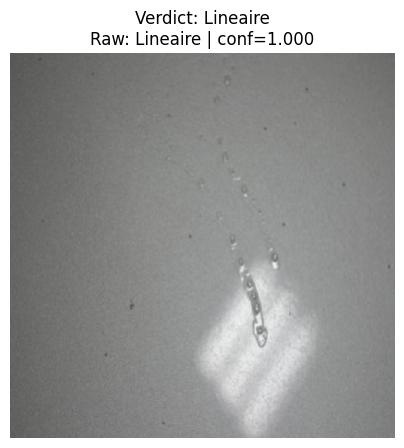

{
  "image_path": "/content/roboflow_paint_defects_binary_morphologie_lineaire_vs_relief/test/Lineaire/DSC_0117_JPG_jpg.rf.2f4bec1e177407f5510cfd247a7259d6.jpg",
  "verdict": "Lineaire",
  "predicted_class_raw": "Lineaire",
  "confidence": 0.9997058510780334,
  "threshold": 0.65,
  "probabilities": {
    "Lineaire": 0.9997058510780334,
    "Relief": 0.000294104334898293
  }
}


In [24]:
# ============================================================
# 14. Fonction d'inférence image individuelle
# ============================================================


def predict_image(image_path, model, class_names, threshold=0.65, img_size=(384, 384), show=True):
    image_path = Path(image_path)
    img = tf.keras.utils.load_img(image_path, target_size=img_size)
    arr = tf.keras.utils.img_to_array(img)
    arr_batch = np.expand_dims(arr, axis=0)

    prob = model.predict(arr_batch, verbose=0)[0]
    pred_idx = int(np.argmax(prob))
    confidence = float(np.max(prob))

    if confidence >= threshold:
        verdict = class_names[pred_idx]
    else:
        verdict = "Incertain"

    result = {
        "image_path": str(image_path),
        "verdict": verdict,
        "predicted_class_raw": class_names[pred_idx],
        "confidence": confidence,
        "threshold": threshold,
        "probabilities": {class_names[i]: float(prob[i]) for i in range(len(class_names))},
    }

    if show:
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        title = f"Verdict: {verdict}\nRaw: {class_names[pred_idx]} | conf={confidence:.3f}"
        plt.title(title)
        plt.axis("off")
        plt.show()
        print(json.dumps(result, indent=2, ensure_ascii=False))

    return result


# Test automatique sur la première image du jeu de test
example_image = test_file_paths[0]
example_result = predict_image(
    example_image,
    model=model,
    class_names=class_names,
    threshold=THRESHOLD_FINAL,
    img_size=IMG_SIZE,
    show=True,
)


Saving Capture d'écran 2026-07-20 143707.png to Capture d'écran 2026-07-20 143707.png


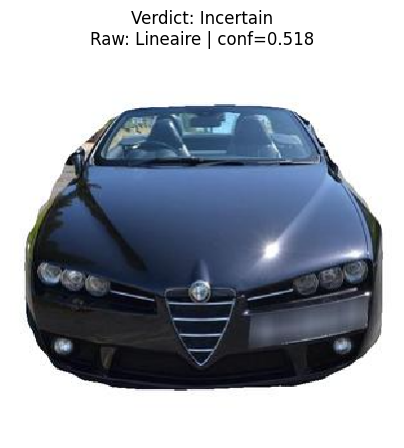

{
  "image_path": "Capture d'écran 2026-07-20 143707.png",
  "verdict": "Incertain",
  "predicted_class_raw": "Lineaire",
  "confidence": 0.5181261897087097,
  "threshold": 0.65,
  "probabilities": {
    "Lineaire": 0.5181261897087097,
    "Relief": 0.48187384009361267
  }
}


In [25]:
# ============================================================
# upload manuel d'une image pour inférence
# ============================================================

# Décommentez pour tester une image locale :
if IN_COLAB:
     from google.colab import files
     uploaded = files.upload()
     for uploaded_name in uploaded.keys():
         predict_image(uploaded_name, model, class_names, threshold=THRESHOLD_FINAL, img_size=IMG_SIZE, show=True)


## 16. Conclusion méthodologique

Ce notebook valide le fichier demandé : **`tests/test_pipeline_binaire.ipynb`**.

Il complète les tests S4 déjà réalisés :

- test EfficientNet-B0 multi-classe Roboflow Paint Defects : architecture validée ;
- test binaire présent : pipeline complet compatible avec la future tâche `Lineaire / Relief` ;
- seuil de rejet `Incertain` validé en post-traitement ;
- sauvegarde des métriques et du modèle validée.

Prochaine étape : remplacer le dataset proxy Roboflow par le dataset propriétaire macroscopique **MALLOULIAUTO v0.1** capturé avec le **Setup F : iPhone 14 Pro + module macroscopique Apexel tout-en-un**.
